In [6]:
%pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu130
%pip install --upgrade pillow matplotlib

Looking in indexes: https://download.pytorch.org/whl/cu130
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import json
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

# Original dataset: one folder per class
SOURCE_DIR = Path(
    r"C:\Users\Dineshraj\OneDrive\Desktop\misc\garbage_classification"
)

# Generated processed dataset
DATA_DIR = Path(
    r"C:\Users\Dineshraj\OneDrive\Desktop\misc\processed_waste_data"
)

# Trained model
MODEL_FILE = Path(
    r"C:\Users\Dineshraj\OneDrive\Desktop\misc\waste_classifier.pth"
)

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 8
LEARNING_RATE = 0.0001
SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# True: regenerate the processed dataset.
# False: reuse the existing complete train/validation/test folders.
REBUILD_DATASET = True

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)
print("CUDA available:", torch.cuda.is_available())
print("Training device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Original dataset folder not found: {SOURCE_DIR}"
    )

# Protect the original source from accidental deletion.
source_resolved = SOURCE_DIR.resolve()
data_resolved = DATA_DIR.resolve()

if (
    source_resolved == data_resolved
    or source_resolved in data_resolved.parents
    or data_resolved in source_resolved.parents
):
    raise ValueError(
        "SOURCE_DIR and DATA_DIR must be separate, non-nested folders."
    )

print("Original dataset:", SOURCE_DIR)
print("Processed dataset:", DATA_DIR)
print("Model output:", MODEL_FILE)

Matplotlib is building the font cache; this may take a moment.


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
CUDA available: True
Training device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
GPU memory: 7.96 GB
Original dataset: C:\Users\Dineshraj\OneDrive\Desktop\misc\garbage_classification
Processed dataset: C:\Users\Dineshraj\OneDrive\Desktop\misc\processed_waste_data
Model output: C:\Users\Dineshraj\OneDrive\Desktop\misc\waste_classifier.pth


In [2]:
# Find the actual category folders.
source_root = SOURCE_DIR

class_folders = sorted(
    p for p in source_root.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)

# Some datasets have an extra wrapper folder.
if len(class_folders) == 1:
    wrapper = class_folders[0]

    root_has_images = any(
        p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        for p in source_root.iterdir()
    )

    wrapper_subdirs = sorted(
        p for p in wrapper.iterdir()
        if p.is_dir() and not p.name.startswith(".")
    )

    if not root_has_images and len(wrapper_subdirs) >= 2:
        source_root = wrapper
        class_folders = wrapper_subdirs

if not class_folders:
    raise ValueError(
        "No category folders found. The dataset must have one "
        "subfolder per class, such as cardboard, glass, metal, etc."
    )

split_names = {"train", "validation", "test", "val", "testing"}

if {p.name.lower() for p in class_folders}.issubset(split_names):
    raise ValueError(
        "SOURCE_DIR points to a folder containing dataset splits, "
        "not class folders. Set it to the original category folders."
    )

print("Classes found:", [p.name for p in class_folders])

# Reuse an existing complete dataset if requested.
required_splits = ["train", "validation", "test"]

dataset_ready = (
    DATA_DIR.is_dir()
    and all(
        (DATA_DIR / split).is_dir()
        and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            for p in (DATA_DIR / split).rglob("*")
        )
        for split in required_splits
    )
)

if not REBUILD_DATASET and dataset_ready:
    print("Using existing processed dataset.")
else:
    if not REBUILD_DATASET:
        raise FileNotFoundError(
            "The processed dataset is incomplete. Set "
            "REBUILD_DATASET = True to recreate it."
        )

    if DATA_DIR.exists():
        print("Removing previous generated dataset:", DATA_DIR)
        shutil.rmtree(DATA_DIR)

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    rng = random.Random(SEED)
    summary = {}

    try:
        for split in required_splits:
            for class_folder in class_folders:
                (DATA_DIR / split / class_folder.name).mkdir(
                    parents=True, exist_ok=True
                )

        for class_folder in class_folders:
            image_paths = sorted(
                p for p in class_folder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            )

            valid_images = []

            # Check image integrity before splitting.
            for image_path in image_paths:
                try:
                    with Image.open(image_path) as image:
                        image.verify()
                    valid_images.append(image_path)
                except Exception as exc:
                    print(f"Skipping unreadable image: {image_path} ({exc})")

            if len(valid_images) < 3:
                raise ValueError(
                    f"Class '{class_folder.name}' contains only "
                    f"{len(valid_images)} valid images. At least 3 "
                    "are required for the three splits."
                )

            rng.shuffle(valid_images)

            n = len(valid_images)
            n_train = max(1, int(n * TRAIN_RATIO))
            n_val = max(1, int(n * VAL_RATIO))

            if n_train + n_val >= n:
                n_train = n - 2
                n_val = 1

            partitions = {
                "train": valid_images[:n_train],
                "validation": valid_images[n_train:n_train + n_val],
                "test": valid_images[n_train + n_val:],
            }

            summary[class_folder.name] = {}

            for split, files in partitions.items():
                output_folder = DATA_DIR / split / class_folder.name
                saved_count = 0

                for index, image_path in enumerate(files):
                    try:
                        with Image.open(image_path) as image:
                            image = ImageOps.exif_transpose(image).convert("RGB")
                            image = image.resize(
                                (IMAGE_SIZE, IMAGE_SIZE),
                                Image.Resampling.LANCZOS
                            )

                            image.save(
                                output_folder / f"{index:06d}.jpg",
                                format="JPEG",
                                quality=95
                            )

                        saved_count += 1

                    except Exception as exc:
                        print(f"Could not process {image_path}: {exc}")

                summary[class_folder.name][split] = saved_count

                if saved_count == 0:
                    raise ValueError(
                        f"No images were processed for "
                        f"{class_folder.name}/{split}."
                    )

            print(
                f"{class_folder.name}: "
                f"train={summary[class_folder.name]['train']}, "
                f"validation={summary[class_folder.name]['validation']}, "
                f"test={summary[class_folder.name]['test']}"
            )

        with open(
            DATA_DIR / "dataset_summary.json",
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(summary, file, indent=2)

        print("\nProcessing and splitting completed.")

    except Exception:
        shutil.rmtree(DATA_DIR, ignore_errors=True)
        raise

print("Processed dataset location:", DATA_DIR)

Classes found: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Removing previous generated dataset: C:\Users\Dineshraj\OneDrive\Desktop\misc\processed_waste_data
battery: train=661, validation=141, test=143
biological: train=689, validation=147, test=149
brown-glass: train=424, validation=91, test=92
cardboard: train=623, validation=133, test=135
clothes: train=3727, validation=798, test=800
green-glass: train=440, validation=94, test=95
metal: train=538, validation=115, test=116
paper: train=735, validation=157, test=158
plastic: train=605, validation=129, test=131
shoes: train=1383, validation=296, test=298
trash: train=487, validation=104, test=106
white-glass: train=542, validation=116, test=117

Processing and splitting completed.
Processed dataset location: C:\Users\Dineshraj\OneDrive\Desktop\misc\processed_waste_data


In [3]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dir = DATA_DIR / "train"
val_dir = DATA_DIR / "validation"
test_dir = DATA_DIR / "test"

for folder in [train_dir, val_dir, test_dir]:
    if not folder.is_dir():
        raise FileNotFoundError(f"Dataset split missing: {folder}")

train_data = datasets.ImageFolder(
    train_dir, transform=train_transform
)
val_data = datasets.ImageFolder(
    val_dir, transform=eval_transform
)
test_data = datasets.ImageFolder(
    test_dir, transform=eval_transform
)

class_names = train_data.classes

if not class_names:
    raise ValueError("No classes found.")

if val_data.classes != class_names or test_data.classes != class_names:
    raise ValueError("Train, validation, and test classes do not match.")

if min(len(train_data), len(val_data), len(test_data)) == 0:
    raise ValueError("A dataset split is empty.")

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Classes:", class_names)
print("Class-to-index mapping:", train_data.class_to_idx)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Class-to-index mapping: {'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}
Training images: 10854
Validation images: 2321
Test images: 2340


In [4]:
weights = MobileNet_V3_Large_Weights.DEFAULT
model = mobilenet_v3_large(weights=weights)

input_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(input_features, len(class_names))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_accuracy = -1.0
best_state = None

MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss_sum = 0.0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

    train_loss = train_loss_sum / len(train_data)

    # Validation phase
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

    val_loss = val_loss_sum / len(val_data)
    val_accuracy = val_correct / len(val_data)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation accuracy: {val_accuracy:.2%}"
    )

model.load_state_dict(best_state)
model = model.to(DEVICE)

print("\nTraining completed.")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\Dineshraj/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21.1M/21.1M [00:00<00:00, 24.2MB/s]


Epoch 1/8 | Train loss: 0.4834 | Validation loss: 0.1491 | Validation accuracy: 95.22%
Epoch 2/8 | Train loss: 0.1595 | Validation loss: 0.1174 | Validation accuracy: 96.73%
Epoch 3/8 | Train loss: 0.0911 | Validation loss: 0.1077 | Validation accuracy: 96.25%
Epoch 4/8 | Train loss: 0.0715 | Validation loss: 0.0982 | Validation accuracy: 96.77%
Epoch 5/8 | Train loss: 0.0554 | Validation loss: 0.1363 | Validation accuracy: 95.65%
Epoch 6/8 | Train loss: 0.0404 | Validation loss: 0.1051 | Validation accuracy: 96.81%
Epoch 7/8 | Train loss: 0.0376 | Validation loss: 0.0996 | Validation accuracy: 97.46%
Epoch 8/8 | Train loss: 0.0378 | Validation loss: 0.1205 | Validation accuracy: 96.60%

Training completed.
Best validation accuracy: 97.46%


Test loss: 0.1079
Test accuracy: 97.65%

Per-class test accuracy:
battery: 98.60% (141/143 images)
biological: 99.33% (148/149 images)
brown-glass: 95.65% (88/92 images)
cardboard: 97.78% (132/135 images)
clothes: 98.62% (789/800 images)
green-glass: 98.95% (94/95 images)
metal: 94.83% (110/116 images)
paper: 99.37% (157/158 images)
plastic: 93.13% (122/131 images)
shoes: 97.99% (292/298 images)
trash: 99.06% (105/106 images)
white-glass: 91.45% (107/117 images)

Model saved to: C:\Users\Dineshraj\OneDrive\Desktop\misc\waste_classifier.pth


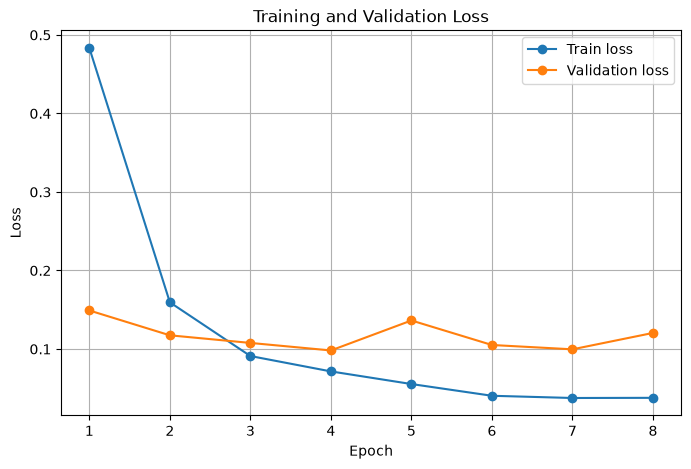

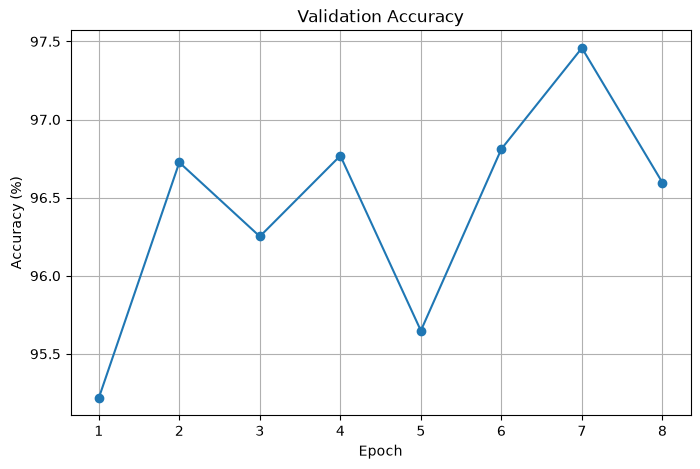

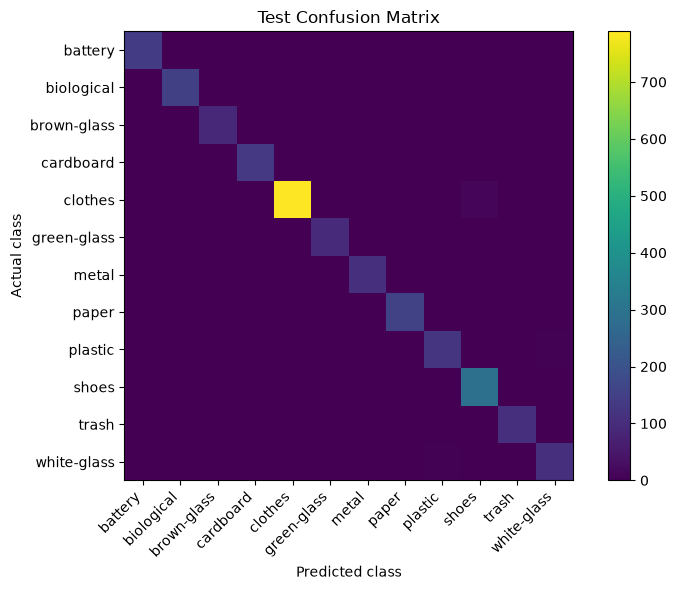

In [9]:
model.eval()

test_loss_sum = 0.0
test_correct = 0
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, labels)
        predictions = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        test_correct += (predictions == labels).sum().item()

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

test_loss = test_loss_sum / len(test_data)
test_accuracy = test_correct / len(test_data)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

# Confusion matrix: rows = actual class, columns = predicted class.
num_classes = len(class_names)
confusion = torch.zeros(
    (num_classes, num_classes), dtype=torch.int64
)

for actual, predicted in zip(all_labels, all_predictions):
    confusion[actual, predicted] += 1

print("\nPer-class test accuracy:")
for i, class_name in enumerate(class_names):
    support = int(confusion[i].sum().item())
    correct = int(confusion[i, i].item())
    accuracy = correct / support if support else 0.0

    print(
        f"{class_name}: {accuracy:.2%} "
        f"({correct}/{support} images)"
    )

# Save model checkpoint and preprocessing settings.
torch.save(
    {
        "model_state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "class_names": class_names,
        "class_to_idx": train_data.class_to_idx,
        "image_size": IMAGE_SIZE,
        "normalization_mean": MEAN,
        "normalization_std": STD,
        "test_accuracy": test_accuracy,
        "best_val_accuracy": best_val_accuracy,
    },
    MODEL_FILE,
)

print("\nModel saved to:", MODEL_FILE.resolve())

# Plot losses.
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot validation accuracy.
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    [value * 100 for value in history["val_accuracy"]],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Validation Accuracy")
plt.grid(True)
plt.show()

# Plot confusion matrix.
plt.figure(figsize=(8, 6))
plt.imshow(confusion.numpy())
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.yticks(range(num_classes), class_names)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Test Confusion Matrix")
plt.colorbar()
plt.tight_layout()
plt.show()

In [10]:
checkpoint = torch.load(
    MODEL_FILE,
    map_location=DEVICE,
    weights_only=True,
)

saved_classes = checkpoint["class_names"]
saved_size = checkpoint["image_size"]
saved_mean = checkpoint["normalization_mean"]
saved_std = checkpoint["normalization_std"]

loaded_model = mobilenet_v3_large(weights=None)
loaded_model.classifier[-1] = nn.Linear(
    loaded_model.classifier[-1].in_features,
    len(saved_classes),
)

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model = loaded_model.to(DEVICE)
loaded_model.eval()

predict_transform = transforms.Compose([
    transforms.Resize((saved_size, saved_size)),
    transforms.ToTensor(),
    transforms.Normalize(saved_mean, saved_std),
])

def predict_waste(image_path, top_k=3):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    with Image.open(image_path) as original:
        image = ImageOps.exif_transpose(original).convert("RGB")

    tensor = predict_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs = loaded_model(tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    k = min(top_k, len(saved_classes))
    top_probs, top_indices = torch.topk(probabilities, k=k)

    print("Predictions:")
    for probability, index in zip(
        top_probs.cpu().tolist(),
        top_indices.cpu().tolist()
    ):
        print(f"{saved_classes[index]}: {probability:.2%}")

    best_index = top_indices[0].item()

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{saved_classes[best_index]}\n"
        f"Confidence: {probabilities[best_index].item():.2%}"
    )
    plt.show()

    return saved_classes[best_index], probabilities[best_index].item()


# Replace this path with the location of an image you want to test.
# predict_waste(
#     r"C:\Users\Dineshraj\OneDrive\Desktop\misc\sample_waste.jpg"
# )